<a href="https://colab.research.google.com/github/Shashank-sketchAl/ML-90-Day-Challenge-/blob/main/Day21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_digits

# Load dataset
data = load_digits()

# Create DataFrame
df = pd.DataFrame(data.data)

# Add target column
df["Target"] = data.target

print(df.head())
print("Dataset shape:", df.shape)

     0    1    2     3     4     5    6    7    8    9  ...   55   56   57  \
0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  8.0  ...  0.0  0.0  0.0   
4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    58    59    60    61   62   63  Target  
0  6.0  13.0  10.0   0.0  0.0  0.0       0  
1  0.0  11.0  16.0  10.0  0.0  0.0       1  
2  0.0   3.0  11.0  16.0  9.0  0.0       2  
3  7.0  13.0  13.0   9.0  0.0  0.0       3  
4  0.0   2.0  16.0   4.0  0.0  0.0       4  

[5 rows x 65 columns]
Dataset shape: (1797, 65)


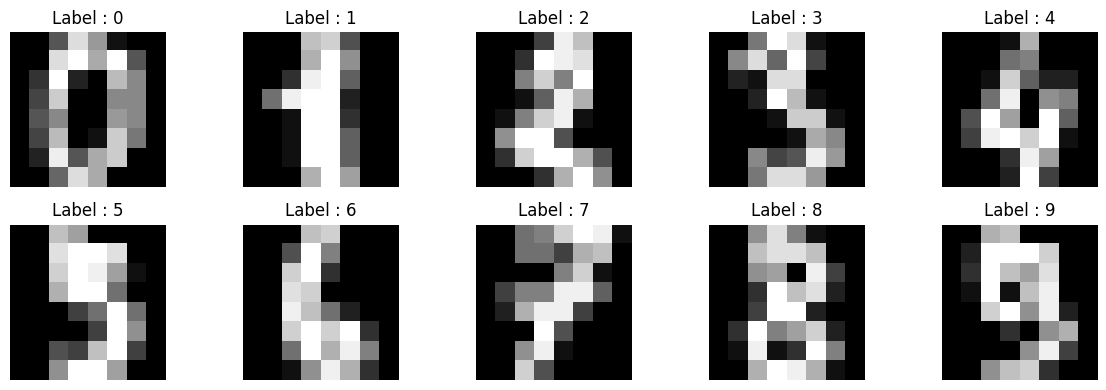

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(data.images[i],cmap="gray")
  plt.title(f"Label : {data.target[i]}")
  plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
X = df.drop("Target",axis=1)
y = df["Target"]

print("Features shape:",X.shape)
print("Target shapes",y.shape)

print("Unique classes:", y.unique())

Features shape: (1797, 64)
Target shapes (1797,)
Unique classes: [0 1 2 3 4 5 6 7 8 9]


In [5]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1437, 64)
Testing features: (360, 64)
Training labels: (1437,)
Testing labels: (360,)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Before scaling:")
print(X_train.iloc[:3, :5])

print("\nAfter scaling:")
print(X_train_scaled[:3, :5])

Before scaling:
       0    1     2     3     4
421  0.0  0.0  11.0  10.0  12.0
825  0.0  0.0   2.0  13.0  15.0
885  0.0  1.0  15.0  16.0  16.0

After scaling:
[[ 0.         -0.33046224  1.2378834  -0.4274473   0.02312659]
 [ 0.         -0.33046224 -0.67096911  0.28074844  0.72032047]
 [ 0.          0.75372553  2.0862623   0.98894419  0.95271842]]


##SVM Implementation

In [7]:
from sklearn.svm import SVC

##SVC -> Support Vector Classification
## used for the clsassification problem

model = SVC(kernel="linear")

model.fit(X_train_scaled,y_train)

print("SVM model trained successfully")

SVM model trained successfully


In [8]:
y_pred = model.predict(X_test_scaled)

print("Actual labels:", y_test.values[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [5 2 8 1 7 2 6 2 6 5]
Predicted labels: [5 2 8 1 7 2 6 2 6 5]


In [9]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)

print("SVM Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

SVM Accuracy: 0.975
Accuracy Percentage: 97.5 %


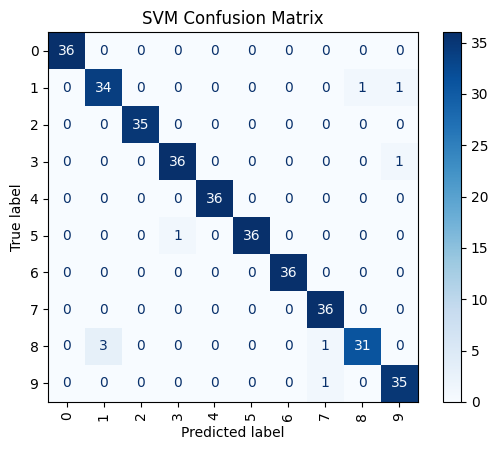

In [10]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test,y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(cmap="Blues", xticks_rotation="vertical")
plt.title("SVM Confusion Matrix")
plt.show()


In [11]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      0.94      0.93        36
           2       1.00      1.00      1.00        35
           3       0.97      0.97      0.97        37
           4       1.00      1.00      1.00        36
           5       1.00      0.97      0.99        37
           6       1.00      1.00      1.00        36
           7       0.95      1.00      0.97        36
           8       0.97      0.89      0.93        35
           9       0.95      0.97      0.96        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



In [12]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

kernels = ["linear", "rbf", "poly"]

results = []

for kernel in kernels:

    model = SVC(kernel=kernel)

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

print(results_df)

   Kernel  Accuracy
0  linear  0.975000
1     rbf  0.975000
2    poly  0.972222


In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "kernel": ["rbf"]
}

grid_search = GridSearchCV(
    SVC(),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV Accuracy: 0.9833018776616338


In [14]:
best_svm = grid_search.best_estimator_

print("Best SVM Model:", best_svm)

Best SVM Model: SVC(C=100, gamma=0.01)


In [15]:
y_pred_best = best_svm.predict(X_test_scaled)

print("Actual labels:", y_test.values[:15])
print("Predicted labels:", y_pred_best[:15])

Actual labels: [5 2 8 1 7 2 6 2 6 5 0 5 9 3 4]
Predicted labels: [5 2 8 1 7 2 6 2 6 5 0 5 9 3 4]


In [16]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred_best)

print("Optimized SVM Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Optimized SVM Accuracy: 0.9833333333333333
Accuracy Percentage: 98.33333333333333 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       0.97      1.00      0.99        36
           7       0.95      1.00      0.97        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [17]:
print("Default Linear SVM Accuracy:", 0.975)

print("Optimized SVM Accuracy:", accuracy)

Default Linear SVM Accuracy: 0.975
Optimized SVM Accuracy: 0.9833333333333333


Support Vector Machine was implemented on the handwritten Digits dataset to classify digits from 0 to 9. Different kernels, including Linear, RBF and Polynomial, were evaluated. Linear and RBF achieved 97.5% accuracy in the initial experiment. GridSearchCV was then used to tune the RBF model's hyperparameters.